In [1]:
import numpy as np
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import scipy
import matplotlib.pyplot as plt
import operator
from jax import config
from functools import partial
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os

import polars as pl
import statistics

In [2]:
from skbio.stats.composition import clr, clr_inv, ilr, ilr_inv
from jax.scipy.optimize import minimize as jmin
from scipy.optimize import minimize, least_squares
from scipy import stats
import optimistix

In [3]:
from emu_example import simple_net, clr_func, clr_inv_func, aitchison, objective_wssr, objective_clr_wssr, calc_ci

In [4]:
solver = optimistix.BFGS(
    rtol=1e-12, atol=1e-12, verbose=frozenset({"step"})
)

In [5]:
# Defining the true fluxes 
M = jnp.array([[-1,-1,2], 
               [0,0,-1], 
               [-1,0,1]])
v1 = 100 
v3 = 50
v5 = 20
v_free = jnp.array([v1,v3,v5]) 
v2, v4, v6 = -M @ v_free

v_true = jnp.array([v1,v2,v3,v4,v5,v6])

# Defining an array with the free fluxes. 
params = jnp.array([v3, v5], dtype=float)
n_params = len(params)

# Define the true MID for the example- 
data = simple_net(params, v1=v1)
print(np.round(data,4))

[1.000e-04 8.008e-01 1.983e-01 9.000e-04]


# Data simulation

In [6]:
# Making simulated data. 
total_mol = 1e5
total_isos = total_mol*data
rng = np.random.default_rng(seed=1234)

sims = 1000
norm_sigma = np.array([1,100,100,10]) 
norm_sigma_cv = total_isos*0.1 # 0.1 is ~10% CV, 0.2 is ~20 % CV
norm_sim = rng.normal(total_isos, norm_sigma_cv, size=(sims,4))

df = pl.from_numpy(norm_sim, schema=["m0", "m1", "m2", "m3"])
df.insert_column(column=(pl.col("m0")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m0_com"), index=4)
df.insert_column(column=(pl.col("m1")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m1_com"), index=5)
df.insert_column(column=(pl.col("m2")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m2_com"), index=6)
df.insert_column(column=(pl.col("m3")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m3_com"), index=7)

m0,m1,m2,m3,m0_com,m1_com,m2_com,m3_com
f64,f64,f64,f64,f64,f64,f64,f64
5.330897,80589.478169,21297.653027,90.245504,0.000052,0.790227,0.208836,0.000885
6.897615,103403.179298,16896.275965,97.293093,0.000057,0.858804,0.14033,0.000808
5.291343,82828.766134,18812.468759,100.655635,0.000052,0.814064,0.184894,0.000989
5.802997,84236.094112,17319.972171,69.696542,0.000057,0.828838,0.170419,0.000686
6.625228,93955.71105,20859.923156,79.980748,0.000058,0.817701,0.181545,0.000696
…,…,…,…,…,…,…,…
6.454028,74916.261438,18176.983263,83.53167,0.000069,0.803967,0.195067,0.000896
6.077571,77471.775527,17199.211979,92.332928,0.000064,0.817477,0.181485,0.000974
6.551042,78201.65358,20058.787127,92.249759,0.000067,0.795062,0.203934,0.000938


In [7]:
f123_sim = jnp.array([statistics.mean(df["m0_com"]), statistics.mean(df["m1_com"]), statistics.mean(df["m2_com"]), statistics.mean(df["m3_com"])])

D_sim = jnp.array([[statistics.stdev(df["m0_com"]),0,0,0], [0,statistics.stdev(df["m1_com"]),0,0], [0,0,statistics.stdev(df["m2_com"]),0], [0,0,0,statistics.stdev(df["m3_com"])]])

## CLR transformed simulations

In [8]:
clr_arr = clr(pl.DataFrame(data= {"m0": df["m0_com"], "m1": df["m1_com"], "m2": df["m2_com"], "m3": df["m3_com"]}))
clr_m0 = np.array([clr_arr[i][0] for i in range(len(clr_arr))])
clr_m1 = np.array([clr_arr[i][1] for i in range(len(clr_arr))])
clr_m2 = np.array([clr_arr[i][2] for i in range(len(clr_arr))])
clr_m3 = np.array([clr_arr[i][3] for i in range(len(clr_arr))])

df_clr = pl.DataFrame(
    data={
        "m0": df["m0_com"], 
        "m1": df["m1_com"],
        "m2": df["m2_com"],
        "m3": df["m3_com"],
        "m0_clr": clr_m0,
        "m1_clr": clr_m1,
        "m2_clr": clr_m2,
        "m3_clr": clr_m3,
    }
)
df_clr

m0,m1,m2,m3,m0_clr,m1_clr,m2_clr,m3_clr
f64,f64,f64,f64,f64,f64,f64,f64
0.000052,0.790227,0.208836,0.000885,-5.186363,4.437241,3.10647,-2.357348
0.000057,0.858804,0.14033,0.000808,-5.01636,4.598855,2.787313,-2.369808
0.000052,0.814064,0.184894,0.000989,-5.195074,4.463385,2.981129,-2.249441
0.000057,0.828838,0.170419,0.000686,-5.017505,4.565499,2.983736,-2.531729
0.000058,0.817701,0.181545,0.000696,-5.026324,4.53337,3.028376,-2.535423
…,…,…,…,…,…,…,…
0.000069,0.803967,0.195067,0.000896,-4.965788,4.393634,2.977419,-2.405266
0.000064,0.817477,0.181485,0.000974,-5.030468,4.422596,2.917545,-2.309673
0.000067,0.795062,0.203934,0.000938,-5.014774,4.372648,3.012024,-2.369898


In [9]:
f123_sim_clr = jnp.array([statistics.mean(df_clr["m0_clr"]), statistics.mean(df_clr["m1_clr"]), statistics.mean(df_clr["m2_clr"]), statistics.mean(df_clr["m3_clr"])])

D_sim_clr = jnp.array([[statistics.stdev(df_clr["m0_clr"]),0,0,0], [0,statistics.stdev(df_clr["m1_clr"]),0,0], [0,0,statistics.stdev(df_clr["m2_clr"]),0], [0,0,0,statistics.stdev(df_clr["m3_clr"])]])

# Estimation of flux with simulated data

## Euclidean space

In [10]:
# Defining initial guess
initial_guess = [100,50]

result_euclidian = optimistix.minimise(objective_wssr, y0=initial_guess, args=(f123_sim, D_sim, v1), solver=solver, max_steps=10000, throw=False)

v3_est, v5_est = result_euclidian.value
print(v3_est, v5_est)

49.06049312072516 20.194504392713103


In [11]:
sensitivity_f123 = jax.jacobian(simple_net, argnums=0)(result_euclidian.value, v1)

Confidence interval based on every single simulation

In [12]:
sims_all = jnp.array([df["m0_com"], df["m1_com"], df["m2_com"], df["m3_com"]])
v3_vec = np.zeros(sims)
v5_vec = np.zeros(sims)
for sim in range(sims):
    data_sim = jnp.array([sims_all[0][sim], sims_all[1][sim], sims_all[2][sim], sims_all[3][sim]])
    result = optimistix.minimise(objective_wssr, y0=initial_guess, args=(data_sim, D_sim, v1), solver=solver, max_steps=100000, throw=False)
    v3_vec[sim], v5_vec[sim] = result.value


In [13]:
v3_CI = jnp.array([np.quantile(v3_vec, 0.025), np.quantile(v3_vec, 0.975)])
v5_CI = jnp.array([np.quantile(v5_vec, 0.025), np.quantile(v5_vec, 0.975)])
print(f"v3 95% CI: ", v3_CI)
print(f"v3 95% CI: ", v5_CI)

v3 95% CI:  [32.85055229 82.63236415]
v3 95% CI:  [16.88787357 23.44261814]


In [14]:
ci_euclidean = calc_ci(result_euclidian, confidence_level=0.95)
print(ci_euclidean)

{'params': Array([49.06049312, 20.19450439], dtype=float64), 'standard_errors': Array([288.84667398,  17.50366491], dtype=float64), 'ci_bounds': Array([[-517.06858493,  615.18957117],
       [ -14.11204842,   54.50105721]], dtype=float64)}


In [15]:
# Create a regular grid for smoother contours
v3_grid = np.linspace(30, 60, 100)
v5_grid = np.linspace(10, 30, 100)
V3, V5 = np.meshgrid(v3_grid, v5_grid)
optimal_value = objective_wssr(result_euclidian.value, args=(f123_sim, D_sim, v1))

# Compute likelihood on the grid
lik_mat = np.zeros_like(V3)
for i in range(V3.shape[0]):
    for j in range(V3.shape[1]):
        lik_mat[i, j] = objective_wssr(params=[V3[i, j], V5[i, j]], args=(f123_sim, D_sim, v1))-optimal_value

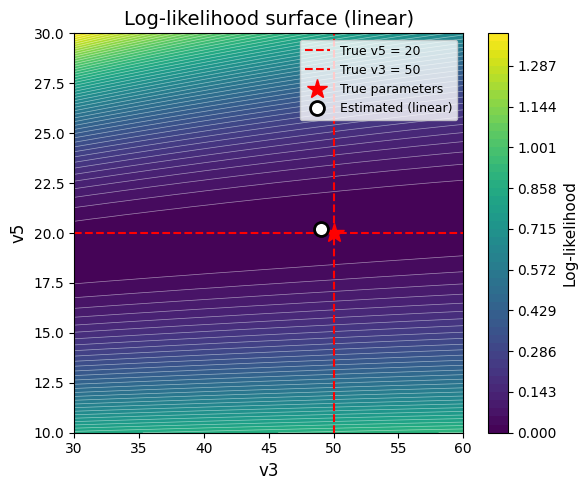

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))

# Use contourf with the grid data
Lmax = lik_mat.max()
levels = np.linspace(lik_mat.min(), Lmax, 50)

cf = ax.contourf(V3, V5, lik_mat, levels=levels, cmap='viridis')
ax.contour(V3, V5, lik_mat, levels=levels, colors='white', linewidths=0.5, alpha=0.5)

# Mark true parameter values
ax.axhline(v5, color='red', linestyle='--', linewidth=1.5, label=f'True v5 = {v5}')
ax.axvline(v3, color='red', linestyle='--', linewidth=1.5, label=f'True v3 = {v3}')
ax.plot(v3, v5, 'r*', markersize=15, label='True parameters')

# Mark estimated values
ax.plot(v3_est, v5_est, 'wo', markersize=10, markeredgecolor='black', markeredgewidth=2, label='Estimated (linear)')

ax.set_xlabel("v3", fontsize=12)
ax.set_ylabel("v5", fontsize=12)
ax.set_title("Log-likelihood surface (linear)", fontsize=14)

# Add colorbar
cbar = plt.colorbar(cf, ax=ax)
cbar.set_label('Log-likelihood', fontsize=11)

ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()

In [17]:
# calculate_ci algoritme from Antoniewicz 2006 
chi2_threshold = 3.84
def run_profile_likelihood(flux_index, start_params, objective_fun, phi_optimal, data, D, v1, direction=1, k_steps=50, step_size=1):
    """
    flux_index: 0 for v3, 1 for v5
    start_params: the full [v3_est, v5_est]
    direction=1 for upper bound, -1 for lower bound
    """
    path = []
    # Start at the optimal value for the flux we are profiling
    current_fixed_val = start_params[flux_index]
    
    # Starting guess for the OTHER flux (the one we aren't profiling)
    other_idx = 1 - flux_index
    current_other_guess = jnp.array([start_params[other_idx]])
    
    print(f"Profiling flux index {flux_index} starting at {current_fixed_val}")
    
    # We want to find the flux value where Phi(u) = target_phi
    # This loop follows the 'At each iteration k' logic from your image

    for k in range(k_steps):
        # Step the fixed flux
        current_fixed_val += direction * step_size
        
        # Inner optimization: Fix one, optimize the rest
        def inner_objective(other_params, args):
            val = args[0]
            # Ensure shape is (2,)
            p = jnp.zeros((2,))
            p = p.at[flux_index].set(val)
            p = p.at[other_idx].set(other_params[0])
            return objective_fun(p, args=(data, D, v1))

        inner_sol = optimistix.minimise(
            inner_objective,
            solver=optimistix.LevenbergMarquardt(rtol=1e-6, atol=1e-6),
            y0=current_other_guess,
            args=(current_fixed_val,),
            max_steps=100000,
            throw=False
        )
        # Update the guess for the next iteration (warm start)
        current_other_guess = inner_sol.value
        # Calculate current Phi(u)
        p_final = jnp.zeros((2,))
        p_final = p_final.at[flux_index].set(current_fixed_val)
        p_final = p_final.at[other_idx].set(current_other_guess[0])

        phi_u = objective_fun(p_final, args=(data, D, v1))
        delta_phi = phi_u - phi_optimal
        path.append((float(current_fixed_val), float(phi_u)))

        # print(f"Step {k}: Flux={current_fixed_val:.2f}, ΔPhi={delta_phi:.4f}")

        if delta_phi > chi2_threshold:
            print("Target Chi2 threshold reached.")
            break
            
    return path

def plot_profile(flux_index, flux_vals, phi_vals, phi_optimal, chi2_threshold, flux_label, result):
    plt.figure(figsize=(8, 5))
    
    plt.plot(flux_vals, phi_vals, 'o-', label='Profile Likelihood', color='teal', markersize=4)
    plt.axvline(result.value[flux_index], color='red', linestyle='--', alpha=0.5, label='MLE')
    
    threshold_val = phi_optimal + chi2_threshold
    
    # ADDED 'r' BEFORE THE STRINGS BELOW:
    # plt.axhline(threshold_val, color='orange', linestyle=':', linewidth=2, 
    #             label=r'95% Threshold ($\Delta\chi^2=3.84$)')
    
    plt.title(f"Profile Likelihood for {flux_label}")
    plt.xlabel(f"Flux Value ({flux_label})")
    plt.ylabel(r"$\Phi(u)$ (WSSR)")
    
    plt.grid(True, which='both', linestyle='--', alpha=0.5)
    plt.legend()
    # plt.ylim(phi_optimal - 0.5, threshold_val + 2)
    plt.show()



In [18]:
# # 1. Calculate the optimal solution residuals Phi(u_hat)
# # phi_optimal = result_euclidian.stats['loss'] # Or re-run objective_wssr(result_euclidian.value, ...)
# phi_optimal = objective_wssr(result_euclidian.value, args=(f123_sim, D_sim, v1))

# # 1. Run for both directions
# flux_index = 0
# profile_up = run_profile_likelihood(flux_index, result_euclidian.value, objective_wssr, phi_optimal, f123_sim, D_sim, v1, direction=1, k_steps=50)
# profile_down = run_profile_likelihood(flux_index, result_euclidian.value, objective_wssr, phi_optimal, f123_sim, D_sim, v1, direction=-1, k_steps=50)

# # 2. Combine and sort data for plotting
# full_profile = np.array(profile_down[::-1] + [(result_euclidian.value[flux_index], phi_optimal)] + profile_up)
# flux_vals = full_profile[:, 0]
# phi_vals = full_profile[:, 1]

In [19]:
# plot_profile(flux_index, flux_vals, phi_vals, phi_optimal, 3.84, flux_label="v3", result=result_euclidian)

In [20]:
# # 1. Run for both directions
# flux_index = 1
# profile_up = run_profile_likelihood(flux_index, result_euclidian.value, objective_wssr, phi_optimal, f123_sim, D_sim, v1, direction=1, k_steps=50)
# profile_down = run_profile_likelihood(flux_index, result_euclidian.value, objective_wssr, phi_optimal, f123_sim, D_sim, v1, direction=-1, k_steps=50)

# # 2. Combine and sort data for plotting
# full_profile = np.array(profile_down[::-1] + [(result_euclidian.value[flux_index], phi_optimal)] + profile_up)
# flux_vals = full_profile[:, 0]
# phi_vals = full_profile[:, 1]
# plot_profile(flux_index, flux_vals, phi_vals, phi_optimal, 3.84, flux_label="v5", result=result_euclidian)

In [21]:
# # Finding the intersection numerically
# upper_bound = np.interp(phi_optimal + 3.84, phi_vals[len(phi_vals)//2:], flux_vals[len(phi_vals)//2:])
# lower_bound = np.interp(phi_optimal + 3.84, phi_vals[:len(phi_vals)//2][::-1], flux_vals[:len(phi_vals)//2][::-1])

# print(f"95% Confidence Interval: [{lower_bound:.2f}, {upper_bound:.2f}]")

In [22]:
# Run optimization
result_clr = optimistix.minimise(objective_clr_wssr, y0=initial_guess, args=(f123_sim_clr, D_sim_clr, v1), solver=solver)
v3_clr, v5_clr = result_clr.value

In [23]:
ci_clr = calc_ci(result_clr, confidence_level=0.95)
print(ci_clr)

{'params': Array([49.36280037, 20.10884177], dtype=float64), 'standard_errors': Array([21.72277029,  3.55098234], dtype=float64), 'ci_bounds': Array([[ 6.78695296, 91.93864778],
       [13.14904427, 27.06863927]], dtype=float64)}


In [24]:
# phi_optimal_clr = objective_clr_wssr(result_clr.value, args=(f123_sim_clr, D_sim_clr, v1))
# flux_index_clr = 1

# # 1. Run for both directions
# profile_up_clr = run_profile_likelihood(flux_index_clr, result_clr.value, objective_clr_wssr, phi_optimal_clr, f123_sim_clr, D_sim_clr, v1, direction=1, k_steps=50)
# profile_down_clr = run_profile_likelihood(flux_index_clr, result_clr.value, objective_clr_wssr, phi_optimal_clr, f123_sim_clr, D_sim_clr, v1, direction=-1, k_steps=50)

# # 2. Combine and sort data for plotting
# full_profile_clr = np.array(profile_down_clr[::-1] + [(result_clr.value[flux_index_clr], phi_optimal_clr)] + profile_up_clr)
# flux_vals_clr = full_profile_clr[:, 0]
# phi_vals_clr = full_profile_clr[:, 1]

In [25]:
# plot_profile(flux_index_clr, flux_vals_clr, phi_vals_clr, phi_optimal_clr, 3.84, flux_label="v5", result=result_clr)

In [26]:
# # 1. Run for both directions
# flux_index_clr = 0
# profile_up_clr = run_profile_likelihood(flux_index_clr, result_clr.value, objective_clr_wssr, phi_optimal_clr, f123_sim_clr, D_sim_clr, v1, direction=1, k_steps=50)
# profile_down_clr = run_profile_likelihood(flux_index_clr, result_clr.value, objective_clr_wssr, phi_optimal_clr, f123_sim_clr, D_sim_clr, v1, direction=-1, k_steps=50)

# # 2. Combine and sort data for plotting
# full_profile_clr = np.array(profile_down_clr[::-1] + [(result_clr.value[flux_index_clr], phi_optimal_clr)] + profile_up_clr)
# flux_vals_clr = full_profile_clr[:, 0]
# phi_vals_clr = full_profile_clr[:, 1]
# plot_profile(flux_index_clr, flux_vals_clr, phi_vals_clr, phi_optimal_clr, 3.84, flux_label="v3", result=result_clr)


Profiling flux index 0 starting at 49.06049312072516
Profiling flux index 0 starting at 49.06049312072516


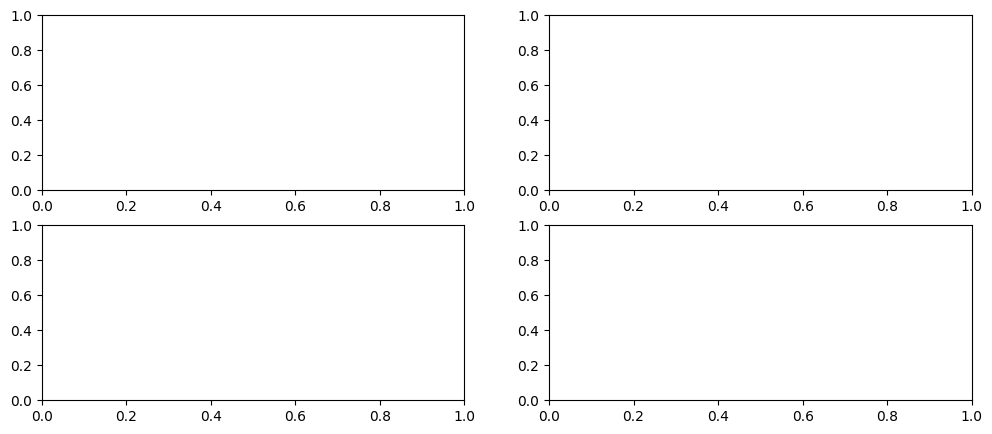

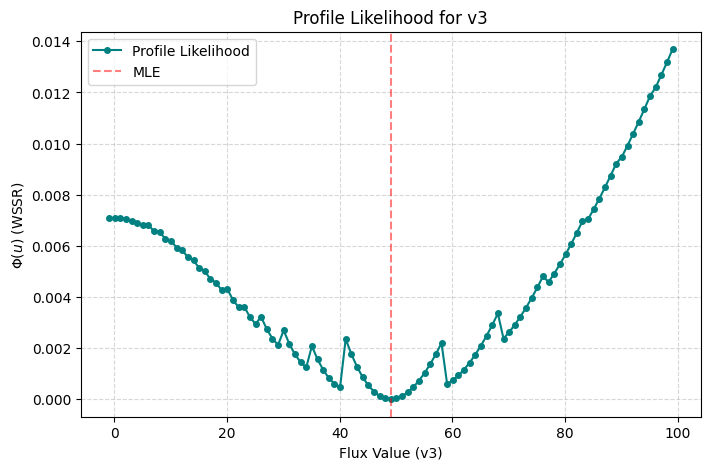

Profiling flux index 0 starting at 49.36280037226727
Profiling flux index 0 starting at 49.36280037226727
Target Chi2 threshold reached.


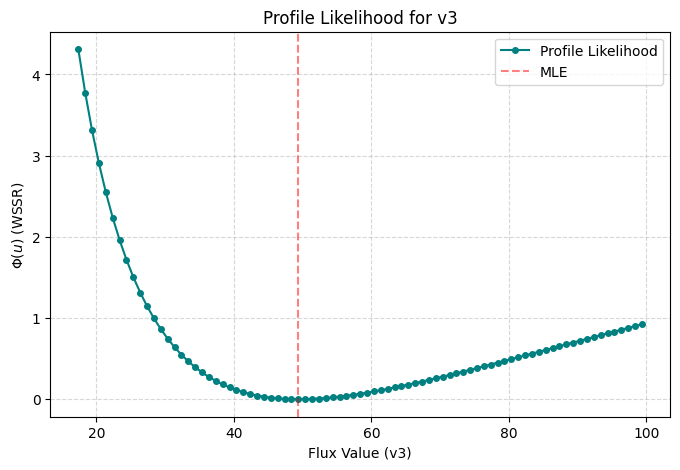

IndexError: index 2 is out of bounds for axis 0 with size 2

In [ ]:
flux_labels = ["v3", "v5"]
phi_optimal = objective_wssr(result_euclidian.value, args=(f123_sim, D_sim, v1))
phi_optimal_clr = objective_clr_wssr(result_clr.value, args=(f123_sim_clr, D_sim_clr, v1))
fig, axes = plt.subplots(2, 2, figsize=(12, 5))
for i in range(2):
    # 1. Run for both directions
    flux_index = i
    profile_up = run_profile_likelihood(flux_index, result_euclidian.value, objective_wssr, phi_optimal, f123_sim, D_sim, v1, direction=1, k_steps=50)
    profile_down = run_profile_likelihood(flux_index, result_euclidian.value, objective_wssr, phi_optimal, f123_sim, D_sim, v1, direction=-1, k_steps=50)

    # 2. Combine and sort data for plotting
    full_profile = np.array(profile_down[::-1] + [(result_euclidian.value[flux_index], phi_optimal)] + profile_up)
    flux_vals = full_profile[:, 0]
    phi_vals = full_profile[:, 1]
    axes[i].plot(plot_profile(flux_index, flux_vals, phi_vals, phi_optimal, 3.84, flux_label=flux_labels[i], result=result_euclidian))
    
    # 1. Run for both directions
    flux_index_clr = i
    profile_up_clr = run_profile_likelihood(flux_index_clr, result_clr.value, objective_clr_wssr, phi_optimal_clr, f123_sim_clr, D_sim_clr, v1, direction=1, k_steps=50)
    profile_down_clr = run_profile_likelihood(flux_index_clr, result_clr.value, objective_clr_wssr, phi_optimal_clr, f123_sim_clr, D_sim_clr, v1, direction=-1, k_steps=50)

    # 2. Combine and sort data for plotting
    full_profile_clr = np.array(profile_down_clr[::-1] + [(result_clr.value[flux_index_clr], phi_optimal_clr)] + profile_up_clr)
    flux_vals_clr = full_profile_clr[:, 0]
    phi_vals_clr = full_profile_clr[:, 1]
    axes[i+2].plot(plot_profile(flux_index_clr, flux_vals_clr, phi_vals_clr, phi_optimal_clr, 3.84, flux_label=flux_labels[i], result=result_clr))



In [32]:
def run_profile_likelihood(flux_index, start_params, objective_fun, phi_optimal, data, D, v1, direction=1, k_steps=50, step_size=1):
    path = []
    chi2_threshold = 3.84
    
    current_fixed_val = float(start_params[flux_index])
    other_idx = 1 - flux_index
    current_other_guess = jnp.array([start_params[other_idx]])
    
    # Track the MLE point itself
    path.append((current_fixed_val, float(phi_optimal)))

    for k in range(k_steps):
        current_fixed_val += direction * step_size
        
        # We pass only the parameter to optimize to the solver
        def inner_objective(other_params, args):
            val, d, mat_D, vec_v1 = args
            p = jnp.zeros((2,))
            p = p.at[flux_index].set(val)
            p = p.at[other_idx].set(other_params[0])
            return objective_fun(p, (d, mat_D, vec_v1))

        inner_sol = optimistix.minimise(
            inner_objective,
            solver=optimistix.LevenbergMarquardt(rtol=1e-6, atol=1e-6),
            y0=current_other_guess,
            args=(current_fixed_val, data, D, v1),
            max_steps=500,
            throw=False
        )
        
        current_other_guess = inner_sol.value
        
        # Reconstruct full vector to calculate final Phi
        p_final = jnp.zeros((2,))
        p_final = p_final.at[flux_index].set(current_fixed_val)
        p_final = p_final.at[other_idx].set(current_other_guess[0])

        phi_u = objective_fun(p_final, (data, D, v1))
        delta_phi = phi_u - phi_optimal
        path.append((float(current_fixed_val), float(phi_u)))

        if delta_phi > chi2_threshold:
            break
            
    return path

def add_profile_to_ax(ax, flux_vals, phi_vals, phi_optimal, mle_val, flux_label):
    ax.plot(flux_vals, phi_vals, 'o-', color='teal', markersize=3, label='Profile')
    ax.axvline(mle_val, color='red', linestyle='--', alpha=0.5, label='MLE')
    
    # threshold_val = phi_optimal + 3.84
    # ax.axhline(threshold_val, color='orange', linestyle=':', label=r'95% CI Thresh')
    
    ax.set_title(f"Profile: {flux_label}")
    ax.set_xlabel(f"Value")
    ax.set_ylabel(r"$\Phi(u)$")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize='small')

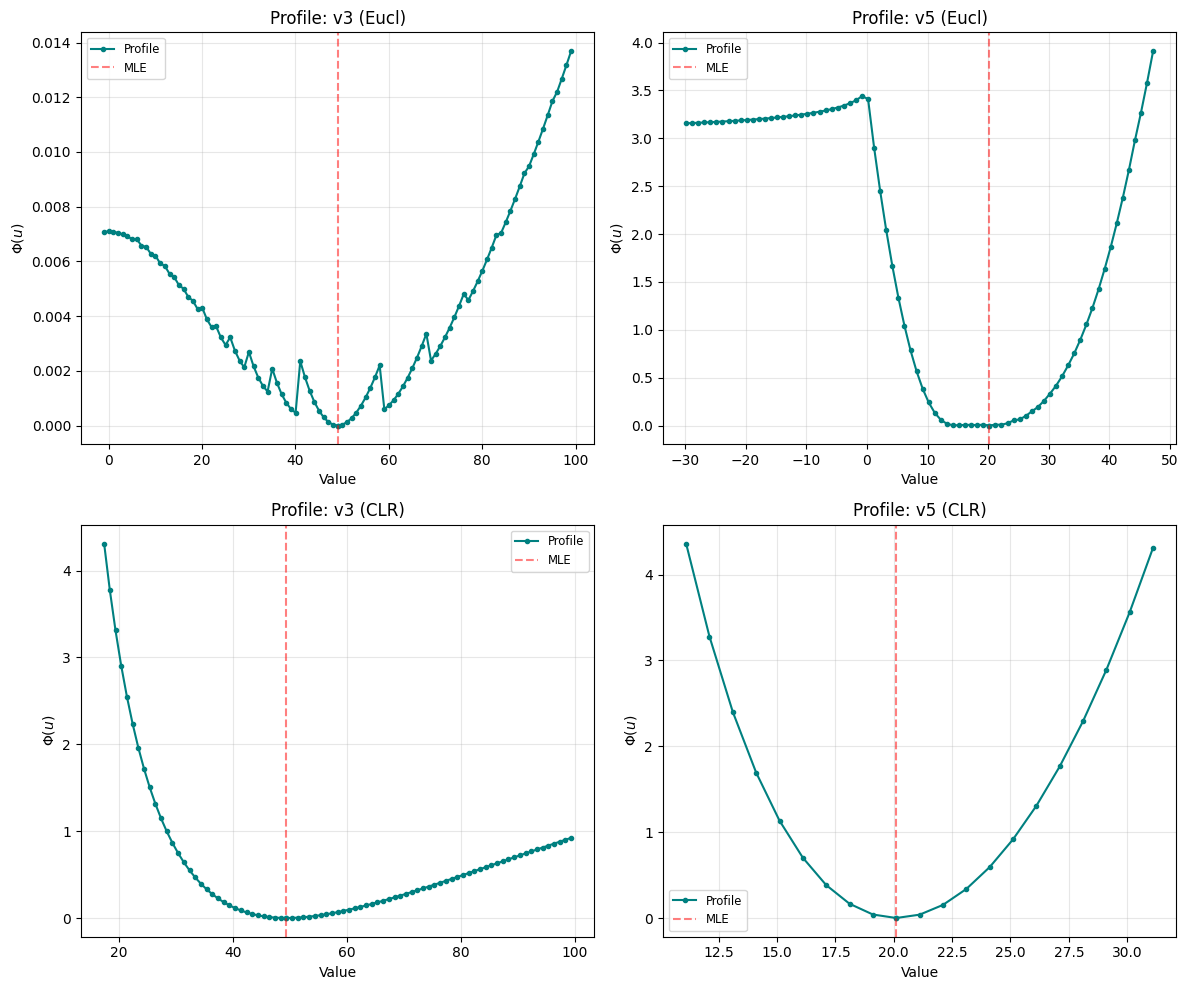

In [33]:
# Setup Figure
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten() # Makes indexing easier: 0, 1, 2, 3

flux_labels = ["v3", "v5"]

for i in range(2):
    # --- EUCLIDEAN SECTION ---
    up = run_profile_likelihood(i, result_euclidian.value, objective_wssr, phi_optimal, f123_sim, D_sim, v1, direction=1)
    down = run_profile_likelihood(i, result_euclidian.value, objective_wssr, phi_optimal, f123_sim, D_sim, v1, direction=-1)
    
    # Combine, sort by flux value, and remove duplicates
    full = sorted(up + down, key=lambda x: x[0])
    flux_v, phi_v = zip(*full)
    
    add_profile_to_ax(axes[i], flux_v, phi_v, phi_optimal, result_euclidian.value[i], f"{flux_labels[i]} (Eucl)")

    # --- CLR SECTION ---
    up_c = run_profile_likelihood(i, result_clr.value, objective_clr_wssr, phi_optimal_clr, f123_sim_clr, D_sim_clr, v1, direction=1)
    down_c = run_profile_likelihood(i, result_clr.value, objective_clr_wssr, phi_optimal_clr, f123_sim_clr, D_sim_clr, v1, direction=-1)
    
    full_c = sorted(up_c + down_c, key=lambda x: x[0])
    flux_vc, phi_vc = zip(*full_c)
    
    add_profile_to_ax(axes[i+2], flux_vc, phi_vc, phi_optimal_clr, result_clr.value[i], f"{flux_labels[i]} (CLR)")

plt.tight_layout()
plt.show()

In [66]:
v_free_clr = np.array([v1,v3_clr,v5_clr])
v2_clr, v4_clr, v6_clr = jnp.dot(-M, v_free_clr)
v_clr = np.array([v1,v2_clr,v3_clr,v4_clr,v5_clr,v6_clr])
print("true flux", v_true)
# print("Etimated linear", v_est)
print("Estimated compositional", v_clr)

true flux [100 110  50  20  20  80]
Estimated compositional [100.         109.14511684  49.36280037  20.10884177  20.10884177
  79.89115823]


In [67]:
print("Simulated data: \n", np.round(f123_sim,4), "\n")
print("True data: \n", np.round(data,4), "\n")
print("Linear: \n", np.round(simple_net(parameters=np.array([v3_est, v5_est]), v1=v1),4), "\n")
print("Compositional: \n", np.round(simple_net(parameters=np.array([v3_clr, v5_clr]), v1=v1),4), "\n")

Simulated data: 
 [1.000e-04 7.983e-01 2.007e-01 9.000e-04] 

True data: 
 [1.000e-04 8.008e-01 1.983e-01 9.000e-04] 

Linear: 
 [1.000e-04 7.983e-01 2.007e-01 9.000e-04] 

Compositional: 
 [1.000e-04 7.993e-01 1.997e-01 9.000e-04] 



NameError: name 'v_est' is not defined

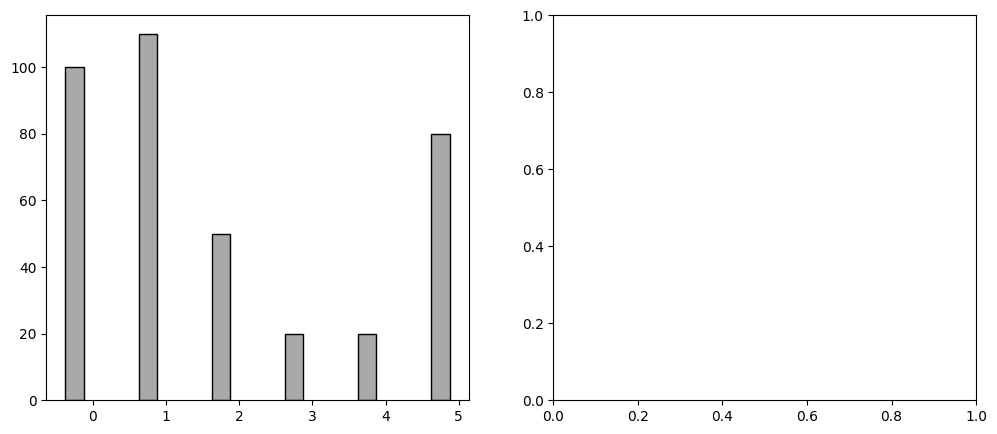

In [68]:
# Comparison plot: Estimated fluxes vs True fluxes
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: Bar chart comparing all fluxes
flux_labels = ['v1', 'v2', 'v3', 'v4', 'v5', 'v6']
x = np.arange(len(flux_labels))
width = 0.25

bars1 = axes[0].bar(x - width, v_true, width, label='True', color='darkgray', edgecolor='black')
bars2 = axes[0].bar(x, v_est, width, label='Linear', color='steelblue', edgecolor='black')
bars3 = axes[0].bar(x + width, v_clr, width, label='CLR', color='coral', edgecolor='black')

axes[0].set_xlabel('Flux', fontsize=12)
axes[0].set_ylabel('Value', fontsize=12)
axes[0].set_title('Estimated vs True Fluxes', fontsize=14)
axes[0].set_xticks(x)
axes[0].set_xticklabels(flux_labels)
axes[0].legend(fontsize=10)
axes[0].set_ylim(0, max(v_true)*1.2)

# Right: Relative error (%) for free parameters only
free_params = ['v3', 'v5']
true_vals = np.array([v3, v5])
linear_vals = np.array([v3_est, v5_est])
clr_vals = np.array([v3_clr, v5_clr])

rel_error_linear = 100 * np.abs(linear_vals - true_vals) / true_vals
rel_error_clr = 100 * np.abs(clr_vals - true_vals) / true_vals

x2 = np.arange(len(free_params))
width2 = 0.35

bars4 = axes[1].bar(x2 - width2/2, rel_error_linear, width2, label='Linear', color='steelblue', edgecolor='black')
bars5 = axes[1].bar(x2 + width2/2, rel_error_clr, width2, label='CLR', color='coral', edgecolor='black')

axes[1].set_xlabel('Free Parameter', fontsize=12)
axes[1].set_ylabel('Relative Error (%)', fontsize=12)
axes[1].set_title('Estimation Error Comparison', fontsize=14)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(free_params)
axes[1].legend(fontsize=10)

# Add value labels on bars
for bar in bars4:
    height = bar.get_height()
    axes[1].annotate(f'{height:.1f}%', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)
for bar in bars5:
    height = bar.get_height()
    axes[1].annotate(f'{height:.1f}%', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)

plt.tight_layout()
plt.show()